# Titanic the first one

In [7]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


import seaborn as sns


from sklearn.linear_model import LogisticRegression


In [8]:


path_file = '../data/raw/train.csv'

df = pd.read_csv(path_file)

df.head(5)





,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
df['Age'].mean().sum()

np.float64(29.69911764705882)

In [12]:
df.iloc[2]

PassengerId                         3
Survived                            1
Pclass                              3
Name           Heikkinen, Miss. Laina
Sex                            female
Age                              26.0
SibSp                               0
Parch                               0
Ticket               STON/O2. 3101282
Fare                            7.925
Cabin                             NaN
Embarked                            S
Name: 2, dtype: object

In [13]:
survived_df = df[df['Survived'] == 1]

not_survived_df = df[df['Survived'] == 0]

survived_df['Survived'].sum()

print(f' Num WOMEN survived : {survived_df[survived_df['Sex'] == 'female'].shape[0]}')

print(f' Num MEN survived : {survived_df[survived_df['Sex'] == 'male'].shape[0]}')











 Num WOMEN survived : 233
 Num MEN survived : 109


In [14]:
pd.crosstab(df['Sex'], df['Survived' ], normalize = 'index')






Survived,0,1
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


In [15]:
df.groupby('Sex')['Survived'].sum()

Sex
female    233
male      109
Name: Survived, dtype: int64

In [16]:
not_survived_df['Age'].mean()


np.float64(30.62617924528302)

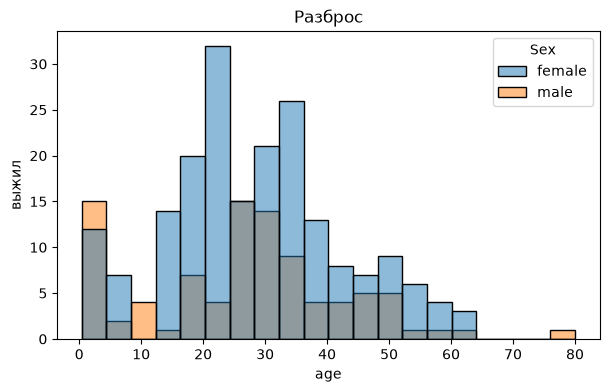

In [17]:
plt.figure(figsize=(7, 4))
sns.histplot(data=survived_df, x = 'Age', bins = 20, hue='Sex', color = 'red', alpha = 0.5)

plt.title('Разброс')
plt.xlabel('age')
plt.ylabel('выжил')
plt.show()


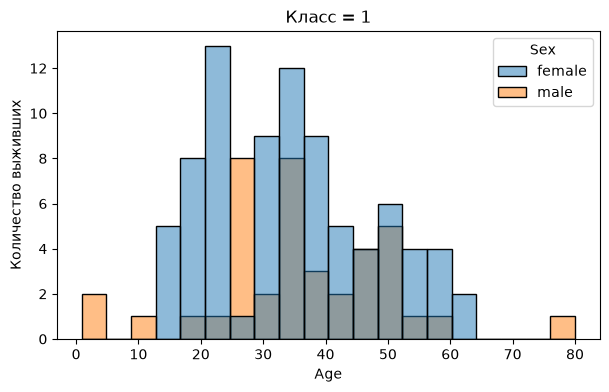

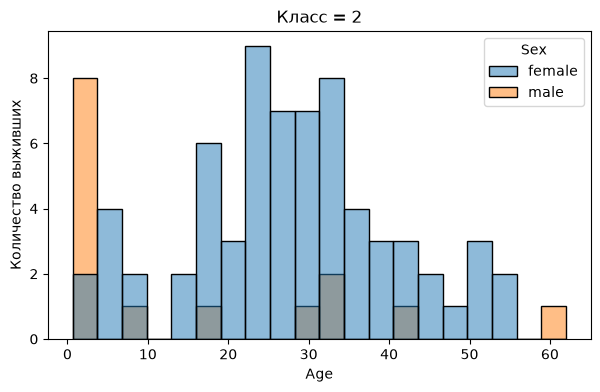

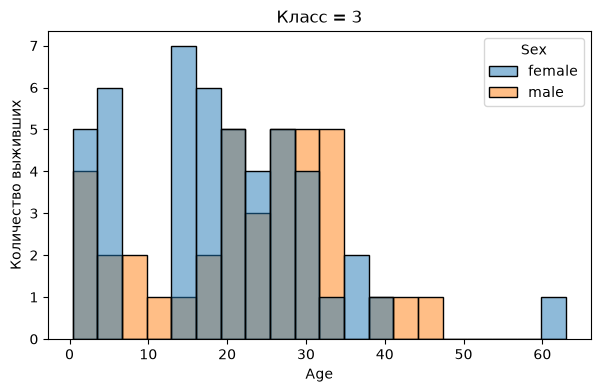

In [18]:
classes = [1, 2, 3]

for i in classes:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=survived_df[survived_df['Pclass'] == i], x='Age',bins=20,hue='Sex',alpha=0.5)

    plt.title(f'Класс = {i}')
    plt.xlabel('Age')
    plt.ylabel('Количество выживших')
    plt.show()

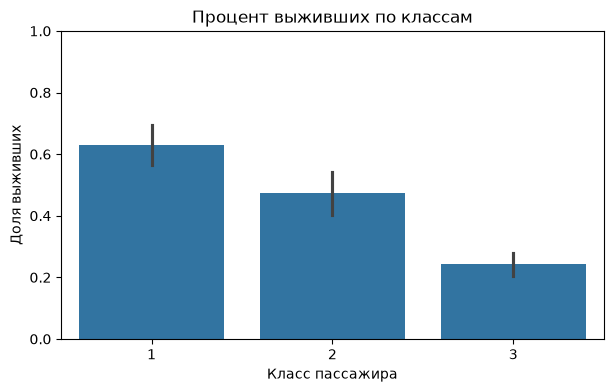

In [19]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df, x='Pclass', y='Survived')

plt.title('Процент выживших по классам')
plt.xlabel('Класс пассажира')
plt.ylabel('Доля выживших')
plt.ylim(0, 1)

plt.show()

<Axes: xlabel='Pclass', ylabel='Survived'>

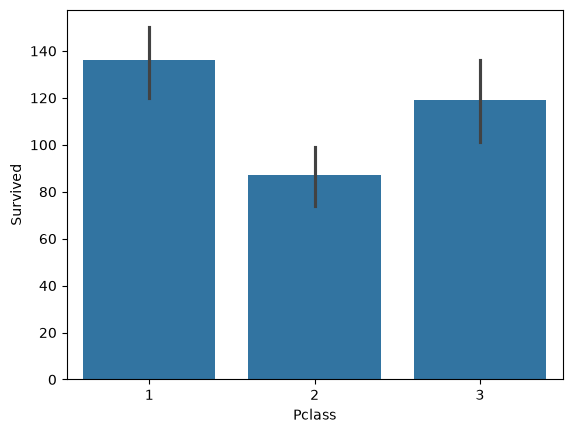

In [20]:
sns.barplot(data=df, x='Pclass', y='Survived', estimator='sum')

In [21]:
df.iloc[np.random.randint(0, len(df))]

PassengerId                          656
Survived                               0
Pclass                                 2
Name           Hickman, Mr. Leonard Mark
Sex                                 male
Age                                 24.0
SibSp                                  2
Parch                                  0
Ticket                      S.O.C. 14879
Fare                                73.5
Cabin                                NaN
Embarked                               S
Name: 655, dtype: object

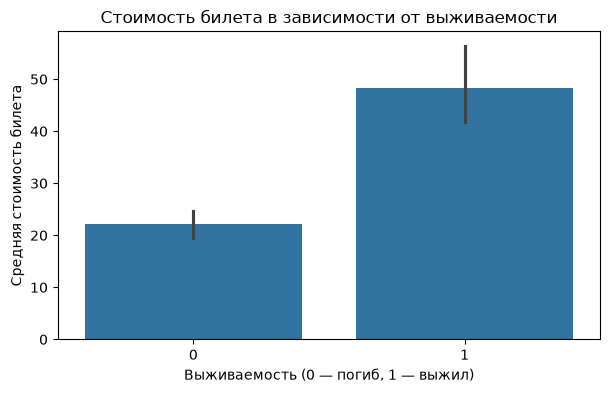

In [22]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df, x='Survived', y='Fare')

plt.title('Стоимость билета в зависимости от выживаемости')
plt.xlabel('Выживаемость (0 — погиб, 1 — выжил)')
plt.ylabel('Средняя стоимость билета')

plt.show()

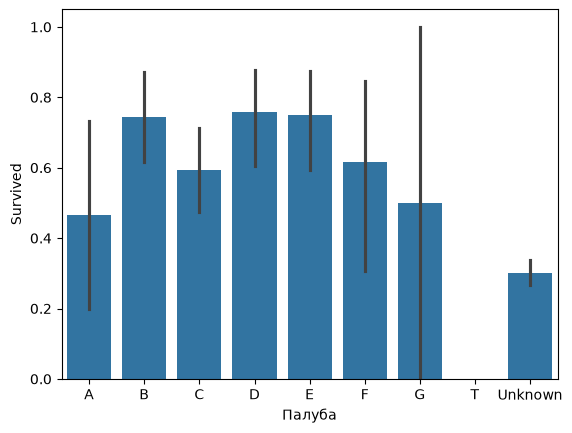

In [23]:
df['Палуба'] = df['Cabin'].str[0].fillna("Unknown")

sns.barplot(data=df, x='Палуба', y='Survived', order=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T','Unknown'])
plt.show()

In [24]:
print(*df.columns, sep = " |-| ")

PassengerId |-| Survived |-| Pclass |-| Name |-| Sex |-| Age |-| SibSp |-| Parch |-| Ticket |-| Fare |-| Cabin |-| Embarked |-| Палуба


In [25]:




    
df.groupby("Палуба")['Survived'].sum()

    

Палуба
A            7
B           35
C           35
D           25
E           24
F            8
G            2
T            0
Unknown    206
Name: Survived, dtype: int64

In [26]:
df.groupby("Палуба")['Fare'].mean()

Палуба
A           39.623887
B          113.505764
C          100.151341
D           57.244576
E           46.026694
F           18.696792
G           13.581250
T           35.500000
Unknown     19.157325
Name: Fare, dtype: float64

In [27]:
df.groupby("Палуба").agg({'Fare': 'mean', 'Survived': 'sum'})


,Fare,Survived
Палуба,,
A,39.623887,7
B,113.505764,35
C,100.151341,35
D,57.244576,25
E,46.026694,24
F,18.696792,8
G,13.581250,2
T,35.500000,0
Unknown,19.157325,206


In [28]:
df[df['Палуба'] == 'Unknown']['PassengerId'].count()



np.int64(687)

In [29]:
df['PassengerId'].count() - df[df['Палуба'] == 'Unknown']['PassengerId'].count()

np.int64(204)

In [43]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Палуба", order=df["Палуба"].value_counts().index)

plt.title("Распределение пассажиров по палубам")
plt.xlabel("Палуба")
plt.ylabel("Количество пассажиров")
plt.show()

KeyError: 'Палуба'

<Figure size 800x500 with 0 Axes>

## Через остальные признаки можно заполнить значение Unknown. через то, как ведут себя палубы. 

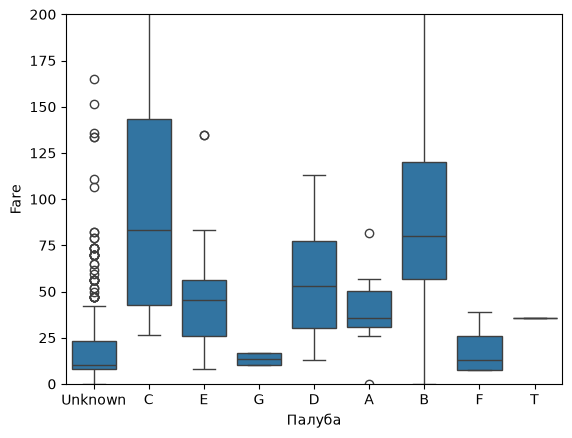

In [31]:
sns.boxplot(data=df, x='Палуба', y='Fare')
plt.ylim(0, 200)
plt.show()

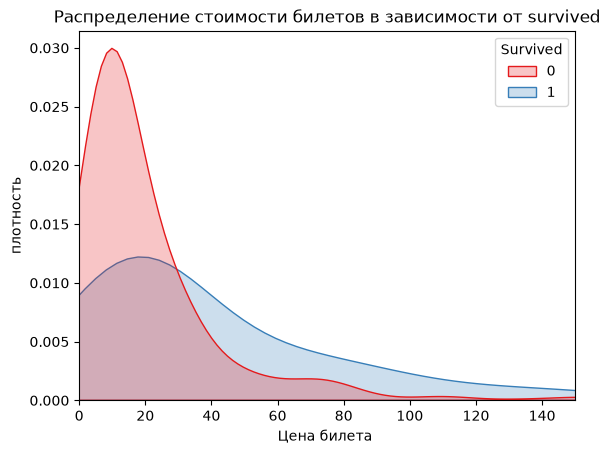

In [32]:
sns.kdeplot(
    data=df, x="Fare", hue="Survived", fill=True, common_norm=False, palette="Set1"
)


plt.xlim(0, 150)

plt.title("Распределение стоимости билетов в зависимости от survived")
plt.xlabel("Цена билета ")
plt.ylabel("плотность")
plt.show()


In [33]:
pd.pivot_table(
    df,
    values="Survived",
    index="Pclass",
    columns="Sex",
    aggfunc=["mean", "count"]
)

mean            count     
Sex       female      male female male
Pclass                                
1       0.968085  0.368852     94  122
2       0.921053  0.157407     76  108
3       0.500000  0.135447    144  347

In [34]:


import sweetviz as sv




report = sv.analyze(df)

report.show_html("sweetviz_report.html")


/home/ecnedaced/projects/kaggle-titanic/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Feature: PassengerId                         |▋         | [  7%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now usin

Report sweetviz_report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


### хочу посмотреть на реляцию между новой фичей - размером семьи - и таргетом. 




In [35]:
df['Family_n'] = df['SibSp'] + df['Parch'] + 1

cols = ['Family_n', 'Survived']

In [36]:





report = sv.analyze(df)

report.show_html("new_report.html")

Feature: PassengerId                         |▋         | [  7%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
Feature: Survived                            |█▎        | [ 13%]   00:01 -> (00:07 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal

Report new_report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


размер семьи и таргет не оч коррелируют. но это нелогично. 

наверное, зависимость нелинейная. 

люди в семье больше 5 человек наверняка имели меньше шанс выжить, но вот 2-3 человека размер   
точно должен был положительно влиять 


In [37]:
df.groupby('Family_n')['Survived'].agg(
    survival_rate = 'mean',
    passengers = 'count'
)

,survival_rate,passengers
Family_n,,
1,0.303538,537
2,0.552795,161
3,0.578431,102
4,0.724138,29
5,0.200000,15
6,0.136364,22
7,0.333333,12
8,0.000000,6
11,0.000000,7


увидел идею создать признак is_alone. 



In [38]:
df['IsAlone'] = (df['Family_n'] == 1)

In [39]:
df.groupby('IsAlone')['Survived'].mean()

IsAlone
False    0.505650
True     0.303538
Name: Survived, dtype: float64

нужно посмотреть насколько эта разница значима --- не является ли она шумом мелкой выборки одной из групп

In [40]:
df.groupby('IsAlone')['Survived'].agg(['count','mean'])

,count,mean
IsAlone,,
False,354,0.505650
True,537,0.303538


In [ ]:
headers = ["Возраст", "Доход", "Город", "Пол", "Высшее_образование"]

data = [
    [24, 45, "Москва", "Женский", 1], 
    [31, 85, "Санкт-Петербург", "Мужской", 1], 
    [45, 60, "Новосибирск", "Мужской", 0],
    [22, 35, "Екатеринбург", "Женский", 0],
    [58, 120, "Москва", "Мужской", 1],
    [29, 75, "Казань", "Женский", 1],
    [38, 50, "Нижний Новгород", "Мужской", 0],
    [19, 25, "Челябинск", "Женский", 0],
    [50, 95, "Санкт-Петербург", "Женский", 1],
    [33, 110, "Москва", "Мужской", 1],
    [41, 65, "Самара", "Мужской", 0]
]

print(data[2][2])  


Новосибирск


In [45]:
print(data)

[[24, 45, 'Москва', 'Женский', 1], [31, 85, 'Санкт-Петербург', 'Мужской', 1], [45, 60, 'Новосибирск', 'Мужской', 0], [22, 35, 'Екатеринбург', 'Женский', 0], [58, 120, 'Москва', 'Мужской', 1], [29, 75, 'Казань', 'Женский', 1], [38, 50, 'Нижний Новгород', 'Мужской', 0], [19, 25, 'Челябинск', 'Женский', 0], [50, 95, 'Санкт-Петербург', 'Женский', 1], [33, 110, 'Москва', 'Мужской', 1], [41, 65, 'Самара', 'Мужской', 0]]


1. вывести всех людей у которых возраст бльше 23
2. вывести всех людей у которых есть высшее образование 
3. вывести всех у которых нет высшелго и доход больше 50 

In [ ]:
n = len(data)


11

In [76]:

n = len(data)

for i in range(0,n+1):
    if i >= 24:
        print(data[i][0])
    


In [70]:
i = 1 

a = data[i][0]